In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import glob
import pyblock
import scipy.stats

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 100,                   # high resolution

    # Axes
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

aa3_to_aa1 = {
    "Ala": "A",
    "Arg": "R",
    "Asn": "N",
    "Asp": "D",
    "Cys": "C",
    "Gln": "Q",
    "Glu": "E",
    "Gly": "G",
    "His": "H",
    "Ile": "I",
    "Leu": "L",
    "Lys": "K",
    "Met": "M",
    "Phe": "F",
    "Pro": "P",
    "Ser": "S",
    "Thr": "T",
    "Trp": "W",
    "Tyr": "Y",
    "Val": "V",
    "Pro_cis": "Pc"
}

def RMSE(pred, true):
    return np.sqrt(np.mean((pred - true) ** 2))


tripeptides = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile','Leu','Lys','Met','Phe','Ser','Thr','Trp','Tyr','Val']


In [12]:

base_path = "../AXA_peptides/"

rho_cutoff = 0.5

df = pd.DataFrame()
df['AA'] = tripeptides

pop_open_M13 = []
pop_open_M13_err = []
rg = []
rg_err = []
code = []

for aa in tripeptides:
    code.append(aa3_to_aa1[aa])
    filepath_M10 = os.path.join(base_path, aa, "SIM", "M13", "fopen.npy")
    filepath_rho = os.path.join(base_path, aa, "SIM", "rho_front_noexcl", "rho_front_frames.npy")
    filepath_rg = os.path.join(base_path, aa, "SIM", "BB_rg_data", "rg_traj_fit.txt")

    if not os.path.isfile(filepath_M10):
        print(f"Skipping {aa}: M10 file not found.")
        continue

    fopenM10 = np.load(filepath_M10)[:,1] # only middle residue
    rho = np.load(filepath_rho)[:,1] # only middle residue
    rho_open = (rho < rho_cutoff) * 1
    O = fopenM10 * rho_open
    rg_data = np.loadtxt(filepath_rg) 

    pop_open_M13.append(np.mean(O))
    rg.append(np.mean(rg_data))

    # errors M11
    reblock_data = pyblock.blocking.reblock(O)
    opt = pyblock.blocking.find_optimal_block(len(O), reblock_data)[0]
    err_fopen_M11 = reblock_data[opt][4]

    # errors rg
    reblock_data = pyblock.blocking.reblock(rg_data)
    opt = pyblock.blocking.find_optimal_block(len(rg_data), reblock_data)[0]
    err_rg = reblock_data[opt][4]

    # append errors
    pop_open_M13_err.append(err_fopen_M11)
    rg_err.append(err_rg)
       

df['p_open_M13'] = np.round(pop_open_M13, 4)
df['p_open_M13 ±'] = np.round(pop_open_M13_err, 4)
df['rg'] = np.round(rg, 4)
df['rg ±'] = np.round(rg_err, 4)
df['aa'] = code

# peptide correction factor - error-weighted average so that most final PFs are between 0.95-1.05

peptide_correction_factor = np.average(df['p_open_M13'], weights=1/df['p_open_M13 ±']**2)
print(peptide_correction_factor)

# calculate protection factors
df["PF_M13"] = np.round(1 / df['p_open_M13'], 4)
df["PF_M13 ±"] = np.round(df['p_open_M13 ±'] / (df['p_open_M13'] ** 2), 4)
df["PF_M13_corr"] = np.round(peptide_correction_factor / df['p_open_M13'], 4)
df["PF_M13_corr ±"] = np.round(df['p_open_M13 ±'] / (df['p_open_M13'] ** 2), 4)

# save
df.to_csv(f'AXA_tripeptides_M13_PF_rg.csv', index=False)








0.9519142195342245


In [13]:
df

,AA,p_open_M13,p_open_M13 ±,rg,rg ±,aa,PF_M13,PF_M13 ±,PF_M13_corr,PF_M13_corr ±
0,Ala,0.9740,0.0014,0.3600,0.0011,A,1.0267,0.0015,0.9773,0.0015
1,Arg,0.9494,0.0028,0.3588,0.0033,R,1.0533,0.0031,1.0026,0.0031
2,Asn,0.9199,0.0041,0.3567,0.0012,N,1.0871,0.0048,1.0348,0.0048
3,Asp,0.8045,0.0126,0.3465,0.0026,D,1.2430,0.0195,1.1832,0.0195
4,Cys,0.9136,0.0041,0.3583,0.0012,C,1.0946,0.0049,1.0419,0.0049
5,Gln,0.9211,0.0060,0.3604,0.0018,Q,1.0857,0.0071,1.0335,0.0071
6,Glu,0.9359,0.0038,0.3555,0.0019,E,1.0685,0.0043,1.0171,0.0043
7,Gly,0.9640,0.0014,0.3495,0.0008,G,1.0373,0.0015,0.9875,0.0015
8,His,0.7779,0.0158,0.3487,0.0022,H,1.2855,0.0261,1.2237,0.0261
9,Ile,0.8766,0.0095,0.3592,0.0016,I,1.1408,0.0124,1.0859,0.0124


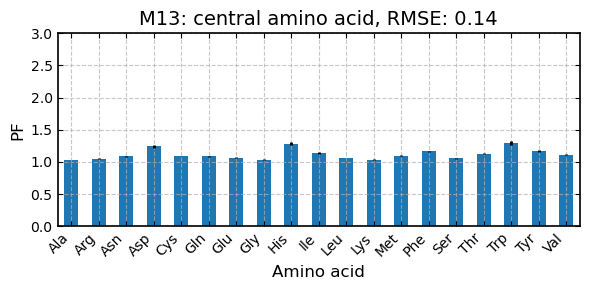

In [14]:
# plot PFs M11 and add RMSE to title

df.plot(x='AA', y='PF_M13', yerr='PF_M13 ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('PF')
plt.xticks(rotation=45, ha='right')  
plt.title('M13: central amino acid, RMSE: {:.2f}'.format(np.round(RMSE(df['PF_M13'], np.ones(len(df))), 4)))
plt.ylim(0,3)
plt.tight_layout()
plt.savefig('PF_M13.png')

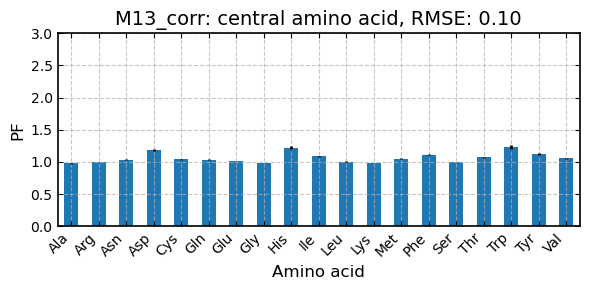

In [15]:
# plot PFs M13 and add RMSE to title

df.plot(x='AA', y='PF_M13_corr', yerr='PF_M13_corr ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('PF')
plt.xticks(rotation=45, ha='right')  
plt.title('M13_corr: central amino acid, RMSE: {:.2f}'.format(np.round(RMSE(df['PF_M13_corr'], np.ones(len(df))), 4)))
plt.ylim(0,3)
plt.tight_layout()
plt.savefig('PF_M13_corr.png')

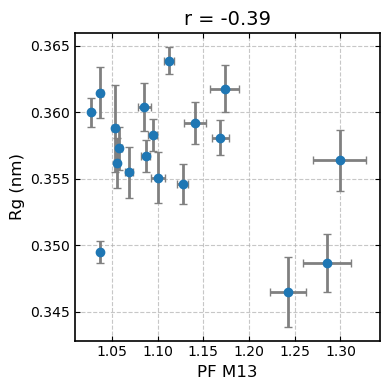

In [16]:
# correlation between PF M13 and rg

plt.figure(figsize=(4, 4))
plt.errorbar(x=df['PF_M13'], y=df['rg'], xerr=df['PF_M13 ±'], yerr=df['rg ±'], fmt='o', ecolor='gray', capsize=3)
plt.xlabel('PF M13')
plt.ylabel('Rg (nm)')
plt.title('r = {:.2f}'.format(scipy.stats.pearsonr(df['PF_M13'], df['rg'])[0]))
plt.tight_layout()
plt.savefig('PF_M13_rg_correlation.png')


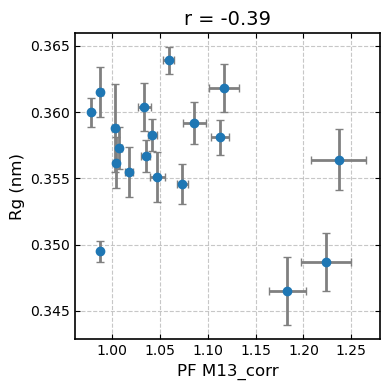

In [17]:
# correlation between PF M11 and rg

plt.figure(figsize=(4, 4))
plt.errorbar(x=df['PF_M13_corr'], y=df['rg'], xerr=df['PF_M13_corr ±'], yerr=df['rg ±'], fmt='o', ecolor='gray', capsize=3)
plt.xlabel('PF M13_corr')
plt.ylabel('Rg (nm)')
plt.title('r = {:.2f}'.format(scipy.stats.pearsonr(df['PF_M13_corr'], df['rg'])[0]))
plt.tight_layout()
plt.savefig('PF_M13_corr_rg_correlation.png')


In [18]:
print(peptide_correction_factor)

0.9519142195342245


In [19]:
np.mean(df['p_open_M13'])

0.8982105263157896

In [20]:
np.average(df['p_open_M13'], weights=1/df['p_open_M13 ±']**2)

0.9519142195342245

In [21]:
df

,AA,p_open_M13,p_open_M13 ±,rg,rg ±,aa,PF_M13,PF_M13 ±,PF_M13_corr,PF_M13_corr ±
0,Ala,0.9740,0.0014,0.3600,0.0011,A,1.0267,0.0015,0.9773,0.0015
1,Arg,0.9494,0.0028,0.3588,0.0033,R,1.0533,0.0031,1.0026,0.0031
2,Asn,0.9199,0.0041,0.3567,0.0012,N,1.0871,0.0048,1.0348,0.0048
3,Asp,0.8045,0.0126,0.3465,0.0026,D,1.2430,0.0195,1.1832,0.0195
4,Cys,0.9136,0.0041,0.3583,0.0012,C,1.0946,0.0049,1.0419,0.0049
5,Gln,0.9211,0.0060,0.3604,0.0018,Q,1.0857,0.0071,1.0335,0.0071
6,Glu,0.9359,0.0038,0.3555,0.0019,E,1.0685,0.0043,1.0171,0.0043
7,Gly,0.9640,0.0014,0.3495,0.0008,G,1.0373,0.0015,0.9875,0.0015
8,His,0.7779,0.0158,0.3487,0.0022,H,1.2855,0.0261,1.2237,0.0261
9,Ile,0.8766,0.0095,0.3592,0.0016,I,1.1408,0.0124,1.0859,0.0124
